# Detección de ejercicios y técnica — Práctica 3

Reconoce **sentadilla, lagartija y curl de bíceps**, cuenta las repeticiones y avisa si cada una está **bien** o **mal** hecha.

**Cómo funciona**
1. MediaPipe detecta 33 puntos del cuerpo en cada cuadro.
2. Con esos puntos se calculan 6 ángulos: rodilla, cadera, codo, hombro, inclinación del torso y línea hombro-cadera-tobillo.
3. **Modelo de ejercicio:** clasifica ventanas de 2 s de ángulos (media, desviación, mínimo y máximo).
4. Las repeticiones se cortan con el ángulo principal (rodilla en sentadilla, codo en lagartija y curl).
5. **Modelo de técnica** (uno por ejercicio): clasifica cada repetición como `bien` o `mal`.

Se comparan Random Forest, SVM y MLP con validación cruzada agrupada por persona y se guarda el mejor.

**Datos:** se entrena con el dataset público *Multi-View Fitness Exercises with Good/Bad Form Labels* (Mendeley Data, 26 personas, CC BY 4.0), vista de perfil. Se pueden agregar videos propios en la misma carpeta.

**Estructura en Google Drive** (la crea el notebook)
```
MyDrive/deteccion_ejercicios/
  videos/
    mendeley_subject_001/sentadilla__bien__side.mp4   <- del dataset (paso 3)
    horta_andrea/sentadilla__mal__1.mp4               <- videos propios (opcional)
  pruebas/        <- videos para probar el modelo ya entrenado
```
Nombre de los videos propios: `ejercicio__etiqueta__n.mp4`, con ejercicio = `sentadilla`, `lagartija` o `curl` y etiqueta = `bien` o `mal`.

Si la carpeta te la compartieron, en Drive haz clic derecho → *Organizar → Agregar acceso directo* a "Mi unidad" para que Colab la vea.

## 1. Preparar el entorno

In [3]:
REPO = "https://github.com/AndreaHortaHernandez/Deteccion-de-ejercicios.git"
import os
if os.path.exists("/content/Deteccion-de-ejercicios"):
    !git -C /content/Deteccion-de-ejercicios pull -q
else:
    !git clone -q $REPO /content/Deteccion-de-ejercicios
%cd /content/Deteccion-de-ejercicios
# --no-deps: evita que MediaPipe instale una segunda copia de OpenCV encima de la de Colab
!pip install -q --no-deps mediapipe==1.2.2
!pip install -q flatbuffers
import pose
pose.asegurar_modelo_pose()
print("Listo")

/content/Deteccion-de-ejercicios
Listo


## 2. Conectar Google Drive

In [4]:
from google.colab import drive
drive.mount("/content/drive")

BASE = "/content/drive/MyDrive/deteccion_ejercicios"   # cámbialo si su carpeta tiene otro nombre
VIDEOS = f"{BASE}/videos"
DATOS = f"{BASE}/datos"        # aquí se guardan los puntos de pose (CSV); así no se recalculan
MODELOS = f"{BASE}/modelos"
SALIDAS = f"{BASE}/salidas"
for p in (DATOS, MODELOS, SALIDAS):
    os.makedirs(p, exist_ok=True)
!ls "$VIDEOS"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ls: cannot access '/content/drive/MyDrive/deteccion_ejercicios/videos': No such file or directory


## 3. Descargar el dataset de Mendeley
Baja la vista de perfil de los 3 ejercicios (~148 videos, ~512 MB) directo a tu Drive. Solo descarga lo que falta, así que si se corta vuelve a correr la celda.

Cita: Duddela Sai Prashanth et al. (2026). *A Multi-View Raw Video Dataset of Seven Fitness Exercises with Good/Bad Form Labels*. Mendeley Data, v2. https://doi.org/10.17632/kgbb3yn47p.2

In [5]:
!python importar_mendeley.py --videos "$VIDEOS"

Leyendo el índice del dataset...
148 videos (512 MB) de 25 personas
  [1/148] mendeley_subject_001/sentadilla__bien__side.mp4
  [2/148] mendeley_subject_002/sentadilla__bien__side.mp4
  [3/148] mendeley_subject_003/sentadilla__bien__side.mp4
  [4/148] mendeley_subject_004/sentadilla__bien__side.mp4
  [5/148] mendeley_subject_005/sentadilla__bien__side.mp4
  [6/148] mendeley_subject_006/sentadilla__bien__side.mp4
  [7/148] mendeley_subject_007/sentadilla__bien__side.mp4
  [8/148] mendeley_subject_008/sentadilla__bien__side.mp4
  [9/148] mendeley_subject_009/sentadilla__bien__side.mp4
  [10/148] mendeley_subject_010/sentadilla__bien__side.mp4
  [11/148] mendeley_subject_011/sentadilla__bien__side.mp4
  [12/148] mendeley_subject_012/sentadilla__bien__side.mp4
  [13/148] mendeley_subject_013/sentadilla__bien__side.mp4
  [14/148] mendeley_subject_014/sentadilla__bien__side.mp4
  [15/148] mendeley_subject_015/sentadilla__bien__side.mp4
  [16/148] mendeley_subject_016/sentadilla__bien__side.m

## 4. Extraer la pose de los videos
Solo procesa videos nuevos o modificados (la primera vez tarda unos minutos). Al final lista los videos con problemas (nombre mal escrito, persona fuera de cuadro…).

In [6]:
!python extraer_videos.py --videos "$VIDEOS" --datos "$DATOS"

148 videos encontrados en /content/drive/MyDrive/deteccion_ejercicios/videos
I0000 00:00:1794021417.293331    4224 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794021417.375362    4224 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794021420.391954    4224 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794021422.799894    4262 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794021422.844458    4262 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. 

## 5. Entrenar y evaluar
Muestra, para cada modelo, la comparación de algoritmos, el reporte por clase y la matriz de confusión.

In [7]:
!python entrenar.py --datos "$DATOS" --modelos "$MODELOS" --salidas "$SALIDAS"

Leyendo sesiones de /content/drive/MyDrive/deteccion_ejercicios/datos ...
Sesiones (videos): 148   Personas: 25 (mendeley_subject_001, mendeley_subject_002, mendeley_subject_003, mendeley_subject_004, mendeley_subject_005, mendeley_subject_006, mendeley_subject_007, mendeley_subject_008, mendeley_subject_009, mendeley_subject_010, mendeley_subject_011, mendeley_subject_012, mendeley_subject_013, mendeley_subject_014, mendeley_subject_015, mendeley_subject_016, mendeley_subject_017, mendeley_subject_018, mendeley_subject_019, mendeley_subject_020, mendeley_subject_021, mendeley_subject_022, mendeley_subject_023, mendeley_subject_024, mendeley_subject_026)
Grupos de validación: persona (mide qué tan bien generaliza a gente nueva)
Videos por ejercicio y etiqueta:
  curl        bien               25
  curl        mal                25
  lagartija   bien               24
  lagartija   mal                24
  sentadilla  bien               25
  sentadilla  mal                25

Ejercicio
Mu

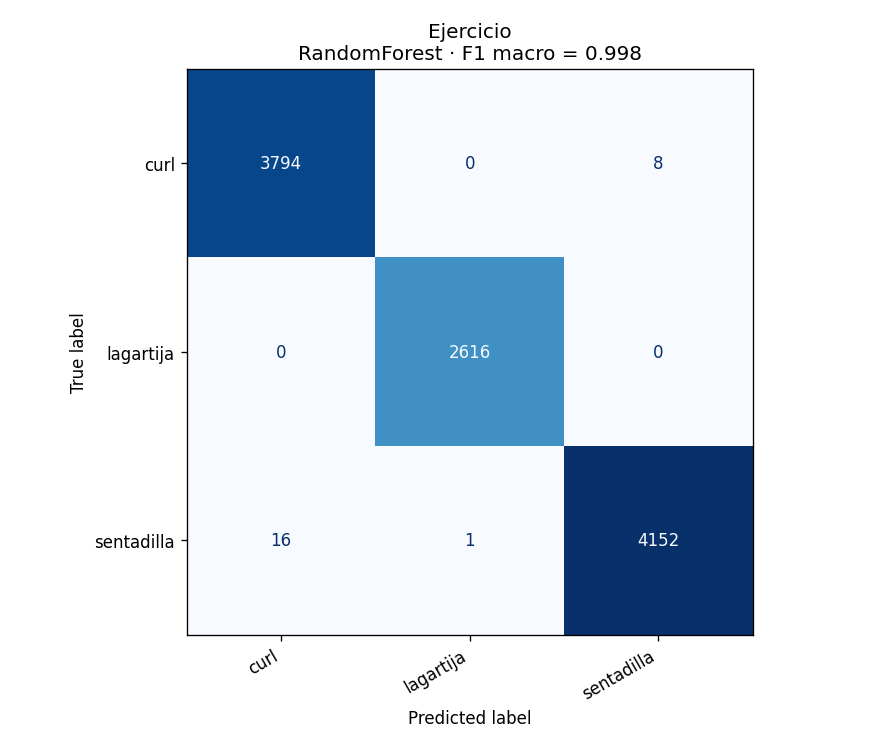

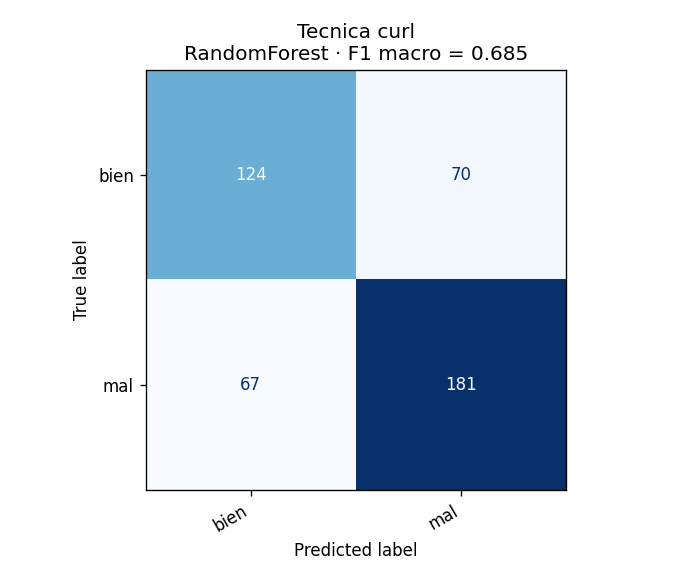

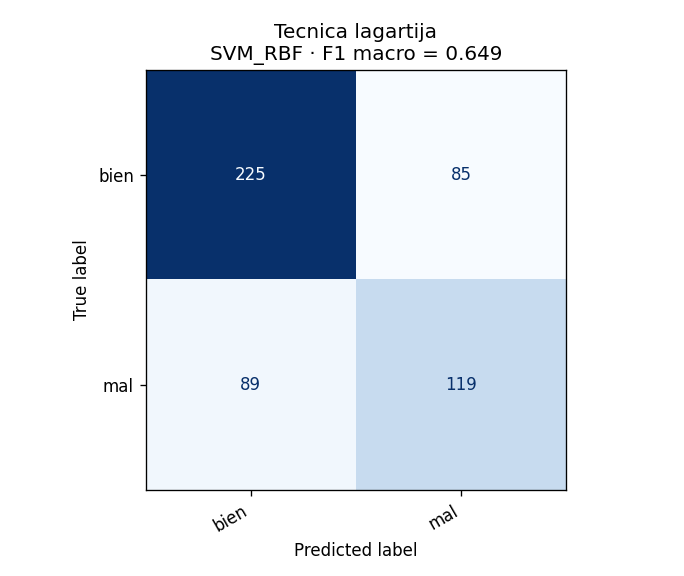

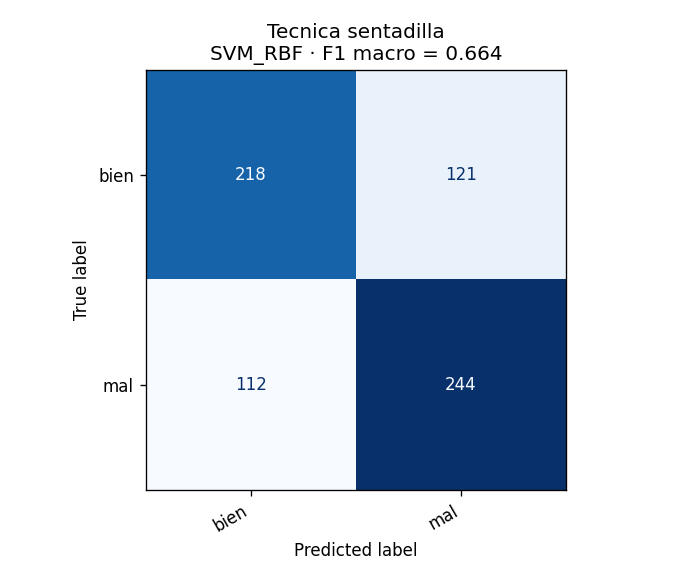

In [8]:
import glob
from IPython.display import Image, display
for png in sorted(glob.glob(f"{SALIDAS}/confusion_*.png")):
    display(Image(png))

## 6. Probar con un video
Usa un video que **no** se haya usado para entrenar (ponlo en `pruebas/` o súbelo aquí).

In [9]:
VIDEO_PRUEBA = f"{BASE}/pruebas/prueba1.mp4"   # o deja "" para subir uno desde tu compu

if not VIDEO_PRUEBA:
    from google.colab import files
    subido = files.upload()
    VIDEO_PRUEBA = "/content/" + next(iter(subido))

!python analizar_video.py --video "$VIDEO_PRUEBA" --salida /content/analizado.mp4 --modelos "$MODELOS"
# convertir a H.264 para que el navegador lo pueda reproducir
!ffmpeg -y -loglevel error -i /content/analizado.mp4 -vcodec libx264 -pix_fmt yuv420p /content/analizado_h264.mp4
from IPython.display import Video
Video("/content/analizado_h264.mp4", embed=True, width=640)

No pude abrir /content/drive/MyDrive/deteccion_ejercicios/pruebas/prueba1.mp4
[in#0 @ 0x5b6fd9e6cc40] Error opening input: No such file or directory
Error opening input file /content/analizado.mp4.
Error opening input files: No such file or directory


## 7. Cámara en vivo
Colab pide permiso para usar la cámara. Colócate **de perfil** y con el cuerpo completo en cuadro.
Va a unos cuantos cuadros por segundo (cada cuadro viaja al servidor de Colab), así que haz las repeticiones a ritmo normal o un poco lento.
Haz clic sobre el video para detener.

In [10]:
import importlib, colab_camara
importlib.reload(colab_camara)
analizador = colab_camara.correr(MODELOS)

<IPython.core.display.Javascript object>

MessageError: NotAllowedError: Permission denied